
### Rebalancing Frequency

This experiment examines how rebalancing frequency affects terminal hedging error under correctly specified volatility and zero transaction costs.

The hedge is rebalanced across a range of intervals, with monthly, weekly and daily rebalancing selected for comparison.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [3]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [4]:
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20
rng = np.random.default_rng(4)

In [16]:
M = 1000000
batch_size = 10000

n_values = [5, 12, 20, 52, 100, 252, 500, 1000]
hist_n = [12, 52, 252]

option_premium, _ = black_scholes_price(S0, K, T, r, sigma)

rmse_values = []
mean_errors = []
hist_errors = {n: [] for n in hist_n}


for n in n_values:

    t_array = np.linspace(0, T, n+1)
    delta_t = T/n
    tau = T - t_array[:-1]

    interest = np.exp(r * tau[1:])

    stats = [0.0, 0.0]


    for start in range(0, M, batch_size):

        batch_M = min(batch_size, M - start)

        randoms = rng.normal(0, np.sqrt(delta_t), size = (batch_M, n))

        brownian = np.zeros((batch_M, n + 1))
        np.cumsum(randoms, axis = 1, out = brownian[:, 1:])

        drift = (r - 0.5 * sigma ** 2) * t_array
        prices = S0 * np.exp(drift + sigma * brownian)

        d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
        delta = norm.cdf(d1)

        option_premium, _ = black_scholes_price(S0, K, T, r, sigma)

        delta_change = np.diff(delta, axis = 1)
        rebalance_costs = delta_change * prices[:, 1:-1]
        total_cost = np.sum(rebalance_costs * interest, axis = 1)

        initial_cash = option_premium - S0 * delta.T[0]
        terminal_cash = initial_cash * np.exp(r * T) - total_cost

        portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]

        call_payoff = np.maximum(prices.T[-1] - K, 0)

        error = portfolio_value - call_payoff

        stats[0] += np.sum(error)
        stats[1] += np.sum(error ** 2)

        if n in hist_n:
            hist_errors[n].append(error)

    mean_errors.append(stats[0] / M)
    rmse_values.append(np.sqrt(stats[1] / M))


### Hedging Error Distributions

Terminal hedging errors are compared for $n = 12, 52, 252$ rebalancing intervals.

More frequent rebalancing is expected to reduce the dispersion of hedging errors, while mean P&L remains approximately zero.

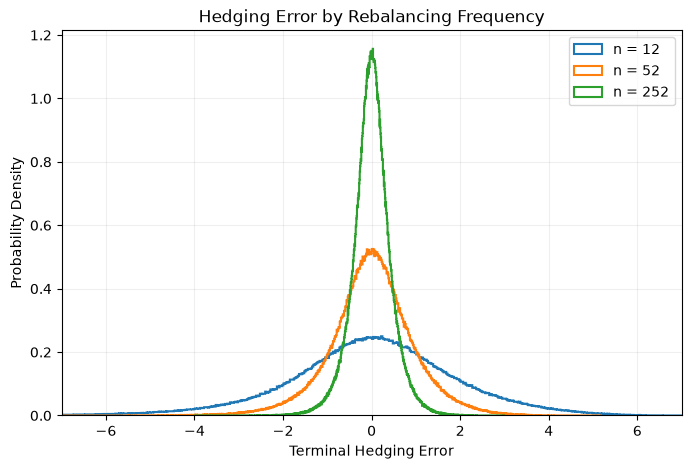

In [21]:
plt.figure(figsize=(8, 5))

for n in hist_n:
    errors_n = np.concatenate(hist_errors[n])

    plt.hist(errors_n, bins=1000, density=True,
             histtype="step", linewidth=1.5, label=f"n = {n}")

plt.xlabel("Terminal Hedging Error")
plt.xlim(-7, 7)
plt.ylabel("Probability Density")
plt.title("Hedging Error by Rebalancing Frequency")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### RMSE Convergence

Hedging accuracy is measured using root mean squared error:

$$
\mathrm{RMSE} = \sqrt{\frac{1}{M}\sum_{i=1}^{M}\varepsilon_i^2}
$$

Under the Black–Scholes assumptions, discrete hedging error is expected to converge at approximately $O(n^{-1/2})$.

Empirical RMSE is compared against this theoretical scaling on a log-log plot.


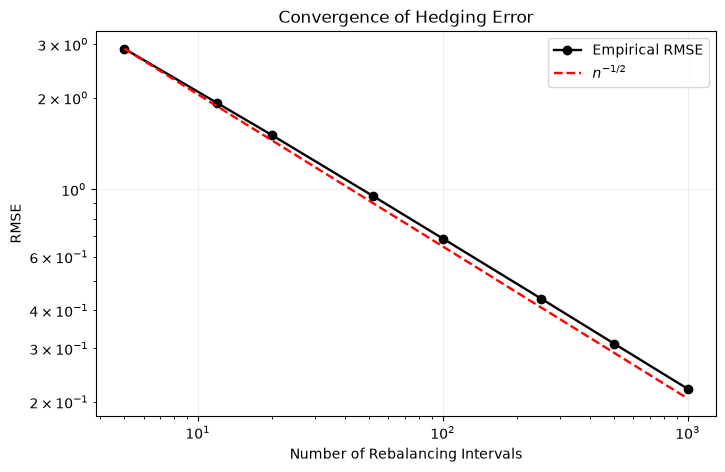

In [26]:
n_array = np.array(n_values)
reference = rmse_values[0] * (n_array / n_array[0])**(-0.5)

plt.figure(figsize=(8, 5))

plt.loglog(n_values, rmse_values, "o-", color = "black", linewidth = 1.7, label="Empirical RMSE")
plt.loglog(n_values, reference, "--", color = "red", linewidth = 1.7, label=r"$n^{-1/2}$")

plt.xlabel("Number of Rebalancing Intervals")
plt.ylabel("RMSE")
plt.title("Convergence of Hedging Error")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### Results

Increasing rebalancing frequency reduces the dispersion of terminal hedging errors, with mean P&L remaining close to zero.

The empirical RMSE approximately follows the expected $n^{-1/2}$ scaling, consistent with decreasing discretisation error.

These results assume frictionless trading. Introducing transaction costs creates a trade-off between hedging accuracy and rebalancing expenses.
